In [12]:
import numpy as np
from pde_find import *

In [13]:
data_2 = np.load('../PDE_Find/dataset/2.npz')
print(data_2.files)

['u', 'x', 't']


In [14]:
u, x, t = data_2['u'], data_2['x'], data_2['t']

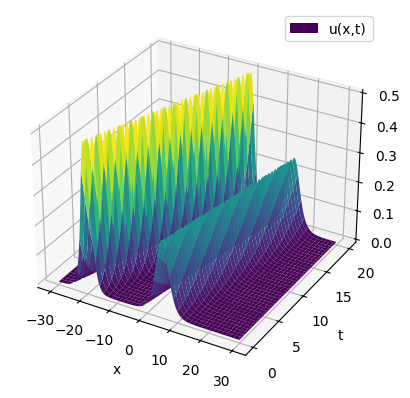

In [15]:
import matplotlib.pyplot as plt

from mpl_toolkits.mplot3d import axes3d

fig, axs = plt.subplots(1, 1, subplot_kw={'projection': '3d'})
axs.plot_surface(x, t, u, cmap='viridis')
plt.xlabel('x')
plt.ylabel('t')
plt.legend(['u(x,t)'])

In [16]:
x

array([[-30.      , -30.      , -30.      , ..., -30.      , -30.      ,
        -30.      ],
       [-29.882812, -29.882812, -29.882812, ..., -29.882812, -29.882812,
        -29.882812],
       [-29.765625, -29.765625, -29.765625, ..., -29.765625, -29.765625,
        -29.765625],
       ...,
       [ 29.648438,  29.648438,  29.648438, ...,  29.648438,  29.648438,
         29.648438],
       [ 29.765625,  29.765625,  29.765625, ...,  29.765625,  29.765625,
         29.765625],
       [ 29.882812,  29.882812,  29.882812, ...,  29.882812,  29.882812,
         29.882812]], dtype=float32)

In [17]:
t

array([[ 0. ,  0.1,  0.2, ..., 19.8, 19.9, 20. ],
       [ 0. ,  0.1,  0.2, ..., 19.8, 19.9, 20. ],
       [ 0. ,  0.1,  0.2, ..., 19.8, 19.9, 20. ],
       ...,
       [ 0. ,  0.1,  0.2, ..., 19.8, 19.9, 20. ],
       [ 0. ,  0.1,  0.2, ..., 19.8, 19.9, 20. ],
       [ 0. ,  0.1,  0.2, ..., 19.8, 19.9, 20. ]], dtype=float32)

In [18]:
dx = x[1,0] - x[0,0]
dt = t[0,1] - t[0,0]
dx, dt

(0.1171875, 0.1)

In [19]:
Ut, Theta, rhs_des = build_linear_system(u, dt, dx, D=3, P=2)
['1'] + rhs_des[1:]

['1',
 'u',
 'u^2',
 'u_{x}',
 'uu_{x}',
 'u^2u_{x}',
 'u_{xx}',
 'uu_{xx}',
 'u^2u_{xx}',
 'u_{xxx}',
 'uu_{xxx}',
 'u^2u_{xxx}']

In [20]:
# Solve with STRidge
w = TrainSTRidge(Theta,Ut,10**-5,5)
print("PDE derived using STRidge")
print_pde(w, rhs_des)

PDE derived using STRidge
u_t = (-5.955400 +0.000000i)uu_{x}
    + (-0.987754 +0.000000i)u_{xxx}
   


In [21]:
Ut_, Theta_, rhs_des_ = build_linear_system(u, dt, dx, D=3, P=3)
['1'] + rhs_des_[1:]

['1',
 'u',
 'u^2',
 'u^3',
 'u_{x}',
 'uu_{x}',
 'u^2u_{x}',
 'u^3u_{x}',
 'u_{xx}',
 'uu_{xx}',
 'u^2u_{xx}',
 'u^3u_{xx}',
 'u_{xxx}',
 'uu_{xxx}',
 'u^2u_{xxx}',
 'u^3u_{xxx}']

In [22]:
# Solve with STRidge
w_ = TrainSTRidge(Theta_,Ut_,10**-5,5)
print("PDE derived using STRidge")
print_pde(w_, rhs_des_)

PDE derived using STRidge
u_t = (-7.255936 +0.000000i)u^2u_{x}
   
